In [43]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import h5py

In [ ]:
use_h5 = True
file_path = r"F:\MarilynIkhane\Marilyn_MEA\MEA Recordings\Data Analysis\Analysis Python\Drongelen H5 data (Python)\N103185\39214_E11\39214_E11_div14_spont_5mins_20250519 spike data after filter drongelen\2025-05-28T14-52-29McsRecording_E-00223.h5"
save_location = r"F:\MarilynIkhane\Marilyn_MEA\Caden Analysis\Jul28Heatmaps\N103262_39076E6_div14.png"

time_step = 1e-06

# Define the synchronicity window (delta_t)
delta_t = 100000  # 50 or 100 ms as a typical value

filter_neurons = True
filter_threshold = 1  # Minimum number of spikes a neuron must have to be included in analysis

In [45]:
if use_h5:
  file = h5py.File(file_path,'r+')
  mapping = {mat[0]:int(mat[2].decode("utf-8").split(' ')[-1]) for mat in file[f'/Data/Recording_0/TimeStampStream/Stream_0/InfoTimeStamp/'][:]}
  electrodes = file['/Data/Recording_0/TimeStampStream/Stream_0/'].keys()
  time_stamp_data = {}
  for ind, electrode in mapping.items():
    try:
      time_stamp_data[electrode] = list(file[f'/Data/Recording_0/TimeStampStream/Stream_0/TimeStampEntity_{ind}'][:][0])
    except KeyError:
      continue
  time_stamp_data = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in time_stamp_data.items()]))
  spike_trains = time_stamp_data
else:
  spike_trains = pd.read_excel(file_path,header=0)

In [46]:
if filter_neurons:
  spike_trains = spike_trains.loc[:, spike_trains.count(0)>=filter_threshold]

min_spike_time = spike_trains.min().min()
max_spike_time = spike_trains.max().max()
total_obs_time = int(max_spike_time - min_spike_time)

# **Spike Time Tiling Coefficient**



- $T_{A}$: the proportion of total recording time which lies within ±Δt of any spike from A. $T_{B}$ is calculated similarly.

- $P_{A}$: the proportion of spikes from A which lie within ±Δt of any spike from B. $P_{B}$ calculated similarly.

- The STTC is calculated as:

  # $STTC = ( \frac{1}{2} \left( \frac{P_{A} - T_{B}}{1 - P_{A}T_{B}} + \frac{P_{B} - T_{A}}{1 - P_{B}T_{A}} \right) )$


In [47]:
# corrected calculation
def compute_T(spikes, delta_t, T_total):
    spikes = np.sort(spikes) # ensure spikes are sorted from lowest time to highest time
    covered = 0 # proportion of recording time covered, starting at zero

    # initial start/end times. First spike time +/- dt, respectively.
    start = max(spikes[0] - delta_t, 0)
    end = min(spikes[0] + delta_t, T_total)

    for spike in spikes[1:]: # iterate through all spikes after the first spike

        # current spike time +/- dt
        new_start = max(spike - delta_t, 0)
        new_end = min(spike + delta_t, T_total)

        # spike overlaps with existing region
        # extend region by setting end time to spike + dt, without moving start time
        if new_start <= end:
            end = max(end, new_end)

        # new_start > end, spike does not overlap existing region, existing region is "completed"
        # add time difference to covered total, and update start and end times to spike +/- dt
        else:
            covered += end - start
            start = new_start
            end = new_end

    covered += end - start # add remaining time difference to covered total
    return covered / T_total # divide covered by recording time to find proportion


def calculate_STTC(spikes_a, spikes_b, delta_t, T=100000):
    """
    Calculate Spike Time Tiling Coefficient between two spike trains.
    
    Parameters:
    -----------
    spikes_a : array-like
        Spike times for neuron A
    spikes_b : array-like
        Spike times for neuron B
    delta_t : float
        Time window
    T : float
        Total recording time
        
    Returns:
    --------
    float
        STTC value
    """
    if len(spikes_a) == 0 or len(spikes_b) == 0:
        return 0.0
    
    # Convert to numpy arrays for faster operations
    spikes_a = np.array(spikes_a)
    spikes_b = np.array(spikes_b)
    
    # Create a 2D matrix of time differences
    time_diff = np.abs(spikes_a[:, np.newaxis] - spikes_b[np.newaxis, :])
    
    # Find spikes within delta_t window
    within_window = time_diff <= delta_t
    
    # Calculate PA and PB (proportion of spikes from one train that fall within 
    # delta_t of any spike from the other train)
    Pa = np.sum(np.any(within_window, axis=1)) / len(spikes_a)
    Pb = np.sum(np.any(within_window, axis=0)) / len(spikes_b)
    
    # Calculate TA and TB (proportion of total recording time that falls within 
    # delta_t of any spike from the train)
    Ta = compute_T (spikes_a, delta_t, T)
    #np.sum(np.any(within_window, axis=1)) * delta_t / T
    Tb = compute_T (spikes_b, delta_t, T)
    #= np.sum(np.any(within_window, axis=0)) * delta_t / T
    
    # Calculate STTC
    if Pa == 1 and Tb == 1:
        part1 = 1
    else:
        part1 = (Pa - Tb) / (1 - Pa * Tb)
        
    if Pb == 1 and Ta == 1:
        part2 = 1
    else:
        part2 = (Pb - Ta) / (1 - Pb * Ta)
    
    STTC = 0.5 * (part1 + part2)
    
    return STTC

def calculate_STTC_from_df(df, delta_t, neuron_a='Neuron A', neuron_b='Neuron B', T=100000):
    """Wrapper function to extract spike times from a DataFrame and calculate STTC"""
    spikes_a = df[neuron_a].dropna().values
    spikes_b = df[neuron_b].dropna().values
    return calculate_STTC(spikes_a, spikes_b, delta_t, T)

def calculate_STTC_pairwise(df, delta_t, T):
    """
    Calculate STTC for all pairs of neurons in the DataFrame.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame where each column represents a neuron and contains spike times
    delta_t : float
        Time window
    T : float
        Total recording time
        
    Returns:
    --------
    pandas.DataFrame
        Matrix of STTC values for each neuron pair
    """
    neurons = df.columns
    n_neurons = len(neurons)
    
    # Pre-extract all spike trains to avoid repeated operations
    spike_trains = {neuron: df[neuron].dropna().values for neuron in neurons}
    
    # Initialize the result matrix
    sttc_matrix = pd.DataFrame(index=neurons, columns=neurons, dtype=float)
    
    # Calculate STTC for each pair
    for i, neuron_a in enumerate(neurons):
        # Set diagonal to 1 (neuron with itself)
        sttc_matrix.loc[neuron_a, neuron_a] = 1.0
        
        # Only compute for j > i to avoid redundant calculations
        for j, neuron_b in enumerate(neurons):
            if j > i:  # Only compute upper triangle
                spikes_a = spike_trains[neuron_a]
                spikes_b = spike_trains[neuron_b]
                
                # Calculate STTC for this pair
                sttc_value = calculate_STTC(spikes_a, spikes_b, delta_t, T)
                
                # Store the value in both positions (symmetric matrix)
                sttc_matrix.loc[neuron_a, neuron_b] = sttc_value
                sttc_matrix.loc[neuron_b, neuron_a] = sttc_value
            elif j < i:
                # Copy value from already computed position (lower triangle)
                sttc_matrix.loc[neuron_a, neuron_b] = sttc_matrix.loc[neuron_b, neuron_a]
    
    return sttc_matrix

In [48]:
df = pd.DataFrame(spike_trains)
delta_t = 50000 # 50 or 100 ms as a typical value
T = total_obs_time

# Calculate the STTC matrix for all neuron pairs
sttc_matrix = calculate_STTC_pairwise(df, delta_t, T)


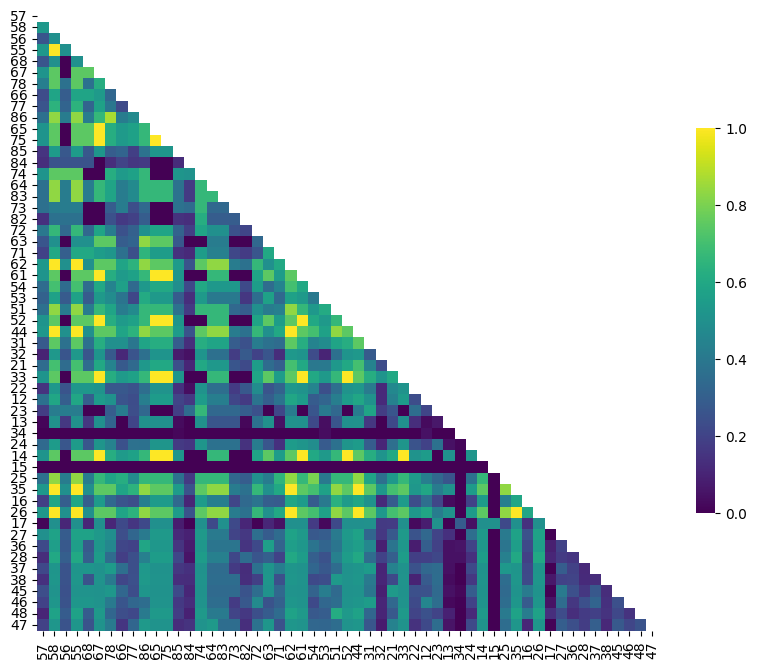

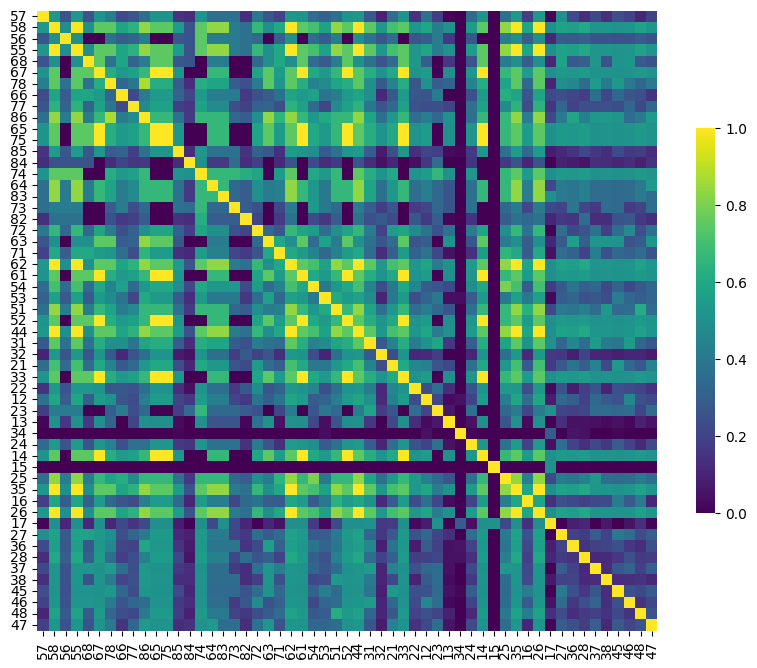

In [49]:
# plt.figure(figsize=(10, 10))
# plt.imshow(sttc_matrix, vmax=1, vmin=0)
# labels = [i.split('. ')[-1] for i in spike_trains.columns]
# plt.xticks(ticks=list(np.arange(0, sttc_matrix.shape[0])), labels=labels)
# plt.yticks(ticks=list(np.arange(0, sttc_matrix.shape[0])), labels=labels)
# plt.colorbar()
# plt.show()


mask = np.triu(np.ones_like(sttc_matrix, dtype=bool))
f, ax = plt.subplots(figsize=(10, 10))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(sttc_matrix,
            mask=mask,
            xticklabels=spike_trains.columns,
            yticklabels=spike_trains.columns,
            cmap='viridis',
            vmin=0,
            vmax=1,
            square=True, linewidths=0, cbar_kws={"shrink": .5})
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()



f, ax = plt.subplots(figsize=(10, 10))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(sttc_matrix,
            xticklabels=spike_trains.columns,
            yticklabels=spike_trains.columns,
            cmap='viridis',
            vmin=0,
            vmax=1,
            square=True, linewidths=0, cbar_kws={"shrink": .5})
plt.xticks(rotation=90)
plt.yticks(rotation=0)
# plt.savefig(save_location)
plt.show()
